<a href="https://colab.research.google.com/github/DVKOMORI/Calculo_Numerico/blob/main/gauss_seidel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cálculo Numérico — Gauss–Seidel

Sistema linear:

$$
\begin{cases}
10x - y + 2z = 6, \\
-x + 11y - z = 22, \\
2x - y + 10z = -10.
\end{cases}
$$

A aproximação inicial é $(x^{(0)}, y^{(0)}, z^{(0)}) = (0, 0, 0)$. A iteração para quando

$$
\left\| x^{(k)} - x^{(k-1)} \right\|_\infty < 10^{-5}.
$$


## 5. Implementação

Em cada equação, a incógnita da diagonal é isolada. Dentro da mesma iteração, o valor novo substitui o antigo assim que é calculado: $y$ usa o $x$ recém-obtido, e $z$ usa o $x$ e o $y$ recém-obtidos.


In [1]:
import numpy as np


def gauss_seidel(A, b, x0=None, tol=1e-5, max_iter=100):
    """Resolve Ax = b pelo método de Gauss–Seidel.

    A parada ocorre quando a norma do máximo da diferença entre
    duas aproximações consecutivas fica abaixo de tol.
    Devolve a solução, o número de iterações e o histórico.
    Cada linha do histórico guarda k, o vetor daquela iteração e o erro.
    A linha k = 0 é a aproximação inicial, sem erro.
    """
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)
    x = np.zeros(n) if x0 is None else np.array(x0, dtype=float)

    historico = [(0, x.copy(), None)]

    for k in range(1, max_iter + 1):
        anterior = x.copy()
        for i in range(n):
            # Soma com os valores já atualizados (antes de i) e os antigos (depois de i).
            soma = np.dot(A[i, :i], x[:i]) + np.dot(A[i, i + 1 :], anterior[i + 1 :])
            x[i] = (b[i] - soma) / A[i, i]
        erro = np.max(np.abs(x - anterior))
        historico.append((k, x.copy(), erro))
        if erro < tol:
            return x, k, historico

    return x, max_iter, historico


A = [
    [10, -1, 2],
    [-1, 11, -1],
    [2, -1, 10],
]
b = [6, 22, -10]

solucao, iteracoes, historico = gauss_seidel(A, b, x0=[0, 0, 0], tol=1e-5)
exata = np.linalg.solve(np.array(A, dtype=float), np.array(b, dtype=float))

print(f"Iterações realizadas: {iteracoes}")
print(f"Solução aproximada:   {solucao}")
print(f"Solução de referência: {exata}")
print(f"Erro em relação à referência: {np.max(np.abs(solucao - exata)):.3e}")


Iterações realizadas: 6
Solução aproximada:   [ 1.00000003  1.99999998 -1.00000001]
Solução de referência: [ 1.  2. -1.]
Erro em relação à referência: 2.690e-08


## 6. Tabela das iterações

A coluna do erro é $\left\| x^{(k)} - x^{(k-1)} \right\|_\infty$. Na aproximação inicial esse valor não existe.


In [2]:
print(f"{'k':>3}  {'x':>12}  {'y':>12}  {'z':>12}  {'erro':>12}")
for k, vetor, erro in historico:
    erro_txt = "—" if erro is None else f"{erro:.6e}"
    print(f"{k:3d}  {vetor[0]:12.6f}  {vetor[1]:12.6f}  {vetor[2]:12.6f}  {erro_txt:>12}")


  k             x             y             z          erro
  0      0.000000      0.000000      0.000000             —
  1      0.600000      2.054545     -0.914545  2.054545e+00
  2      0.988364      2.006711     -0.997002  3.883636e-01
  3      1.000071      2.000279     -0.999986  1.170777e-02
  4      1.000025      2.000004     -1.000005  2.755404e-04
  5      1.000001      2.000000     -1.000000  2.389216e-05
  6      1.000000      2.000000     -1.000000  1.262607e-06


## 7. Gráficos

O primeiro gráfico mostra as três incógnitas ao longo das iterações. O segundo mostra o erro entre iterações consecutivas em escala logarítmica.


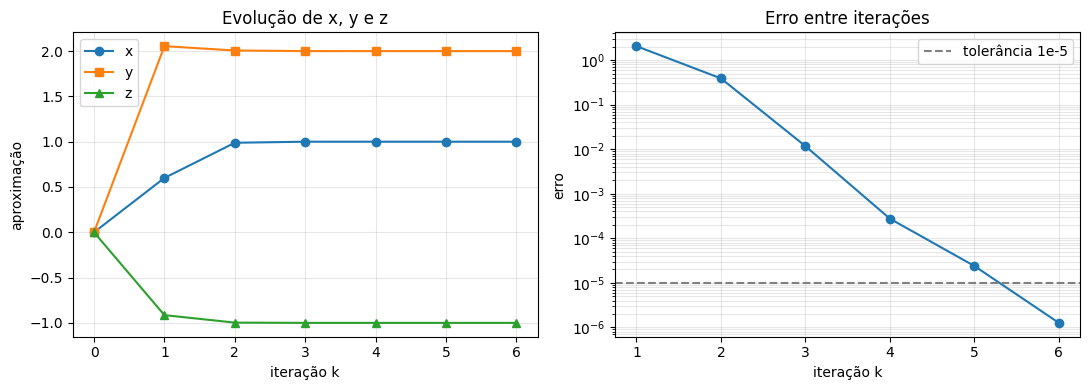

In [3]:
import matplotlib.pyplot as plt

ks = [item[0] for item in historico]
xs = [item[1][0] for item in historico]
ys = [item[1][1] for item in historico]
zs = [item[1][2] for item in historico]
erros_k = [item[0] for item in historico if item[2] is not None]
erros = [item[2] for item in historico if item[2] is not None]

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))

eixos[0].plot(ks, xs, "o-", label="x")
eixos[0].plot(ks, ys, "s-", label="y")
eixos[0].plot(ks, zs, "^-", label="z")
eixos[0].set_xlabel("iteração k")
eixos[0].set_ylabel("aproximação")
eixos[0].set_title("Evolução de x, y e z")
eixos[0].set_xticks(ks)
eixos[0].legend()
eixos[0].grid(True, alpha=0.3)

eixos[1].semilogy(erros_k, erros, "o-")
eixos[1].axhline(1e-5, color="gray", linestyle="--", label="tolerância 1e-5")
eixos[1].set_xlabel("iteração k")
eixos[1].set_ylabel("erro")
eixos[1].set_title("Erro entre iterações")
eixos[1].set_xticks(erros_k)
eixos[1].legend()
eixos[1].grid(True, which="both", alpha=0.3)

fig.tight_layout()
plt.show()
